# Task 4 Track A — a walkthrough of every module

This notebook opens each part of `src/task4/`, says what it does, gives the
mathematics it implements, and runs it on real data from the release.

It is meant to be read top to bottom once, then used as a bench: change a number
in a cell, re-run that cell, see what moves. When you are done playing here, the
same code runs from the command line through `task4.cli`, and the last section
shows those commands.

**The task.** You are given three story summaries: an anchor $a$ and two
candidates $b_1, b_2$. Decide which candidate is narratively closer to the
anchor. Every layer in this project answers that question the same way: it
defines a similarity function $s(\cdot,\cdot)$ and predicts

$$\hat{y} = \mathbb{1}\left[\, s(a, b_1) \ge s(a, b_2) \,\right]$$

So a layer is nothing but a choice of $s$. That is the whole design.

In [1]:
import json, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "raw" / "narrative-similarity-dataset"
RESULTS = ROOT / "reports" / "results"
FIGURES = ROOT / "reports" / "figures"
print("project root:", ROOT)
print("dataset present:", DATA.exists())

project root: /sessions/rcw-016vcecvwuwkv8wsitwov6u5/mnt/Projects/semeval2026-task4
dataset present: True


---
## 1. `dataset.py` — turning files into objects

The release ships JSON Lines: one JSON object per line. This module reads those
lines into a `Triple`, so nothing downstream ever has to know the file format.

A `Triple` carries the three texts, the gold label (`a_is_closer`), and three
lists of annotator flags — one list per similarity aspect. Each list has one
entry per annotator, `True` if that annotator said this aspect drove the
decision.

Two derived properties matter later:

- `n_annotators` — 2 for most items, 3 where a third was called in to break a tie
- `unanimous` — whether the annotators agreed on the binary label

In [2]:
from task4.dataset import load_triples, Triple

dev = load_triples(DATA / "dev" / "dev_track_a.jsonl")
print(f"{len(dev)} dev triples")

t = dev[0]
print("\nanchor :", t.anchor[:110], "...")
print("cand A :", t.text_a[:110], "...")
print("cand B :", t.text_b[:110], "...")
print("\ngold: A is closer =", t.a_is_closer)
print("annotators:", t.n_annotators, "| unanimous:", t.unanimous)
print("aspect flags -> outcomes:", t.outcomes,
      "| course_of_actions:", t.course_of_actions,
      "| abstract_theme:", t.abstract_theme)

200 dev triples

anchor : The book follows an international organization named the Ministry for the Future in its mission to act as an a ...
cand A : The old grandmother Tina arrives in town to attend the wedding of his nephew Alberto with his girlfriend Ilean ...
cand B : The nano-plague that poisoned Earth's water supply has reached its 60-year critical mass. The Unlight enemy fo ...

gold: A is closer = False
annotators: 2 | unanimous: True
aspect flags -> outcomes: [True, False] | course_of_actions: [True, False] | abstract_theme: [True, True]


In [3]:
from collections import Counter

print("annotators per item:", dict(Counter(x.n_annotators for x in dev)))
print("unanimous:", sum(x.unanimous for x in dev), "of", len(dev))
print("label balance (A closer):", sum(bool(x.a_is_closer) for x in dev), "of", len(dev))
lens = sorted(len(x.anchor.split()) for x in dev)
print("anchor length in words -> median", lens[len(lens)//2], "range", lens[0], "-", lens[-1])

annotators per item: {2: 166, 3: 34}
unanimous: 166 of 200
label balance (A closer): 101 of 200
anchor length in words -> median 116 range 48 - 288


The third annotator appears **only** where the first two disagreed. That is why
"unanimous" and "two annotators" turn out to be the same set — a fact that
matters in section 7.

---
## 2. `scorers/base.py` — the one interface

Every layer subclasses `Scorer` and implements a single method:

```python
def score(self, anchor: str, candidate: str) -> float
```

Higher means more similar. The base class supplies `predict`, which applies the
decision rule from the top of this notebook to a whole split, and `fit`, which
does nothing unless a layer needs a pass over the corpus first.

Because the interface is this narrow, a new idea is a new `score` and nothing
else. The harness, the statistics and the plots never change.

In [4]:
from task4.scorers.base import Scorer

class LengthScorer(Scorer):
    """A deliberately silly layer: prefer the candidate closest in length.

    Written here only to show how little it takes to add one."""
    name = "demo_length"
    def score(self, anchor, candidate):
        return -abs(len(anchor.split()) - len(candidate.split()))

preds = LengthScorer().predict(dev)
hits = sum(p == bool(t.a_is_closer) for p, t in zip(preds, dev))
print(f"length heuristic: {100*hits/len(dev):.2f}% on dev  (chance is 50)")

length heuristic: 48.50% on dev  (chance is 50)


---
## 3. L0 and L1 — the lexical layers

### Jaccard overlap

Treat each story as a **set** of word types. For two sets $A$ and $B$:

$$J(A,B) = \frac{|A \cap B|}{|A \cup B|}$$

It is 1 when the vocabularies are identical and 0 when they share nothing. It
ignores word order, repetition and meaning entirely — which is the point. It
measures how much of the task is solvable by surface overlap alone.

### TF-IDF cosine

Each story becomes a vector over terms. Term $t$ in document $d$ gets

$$w_{t,d} = \left(1 + \log \mathrm{tf}_{t,d}\right) \cdot \log \frac{N}{\mathrm{df}_t}$$

The first factor dampens repetition (sublinear term frequency); the second
discounts terms that appear in many documents. Similarity is the cosine of the
angle between the two vectors:

$$\cos(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\|\,\|\mathbf{v}\|}$$

**Where the document frequencies come from matters.** $\mathrm{df}_t$ is counted
over whatever split `fit()` is given. Count it over dev *and* test and you have
leaked test information into a dev number. This project fits on dev alone, which
is why the dev TF-IDF figure here is **51.50**, not the 49.0 that appeared in
the proposal under the leaky protocol.

In [5]:
from task4.scorers.lexical import JaccardScorer, TfidfScorer, RandomScorer, tokenize

print("tokenizer:", tokenize("The Dog's, bark! 3 times"))

jac = JaccardScorer()
a, b = "a knight rescues a princess from a dragon", "a princess is rescued from a dragon"
c = "a chemist synthesises a compound in a laboratory"
print(f"\nJ(anchor, related)   = {jac.score(a,b):.3f}")
print(f"J(anchor, unrelated) = {jac.score(a,c):.3f}")

tokenizer: ['the', "dog's", 'bark', '3', 'times']

J(anchor, related)   = 0.500
J(anchor, unrelated) = 0.091


In [6]:
def run(scorer, triples, label):
    scorer.fit(triples)
    preds = scorer.predict(triples)
    correct = [p == bool(t.a_is_closer) for p, t in zip(preds, triples)]
    print(f"{label:<14} {100*sum(correct)/len(correct):6.2f}%")
    return correct

print("accuracy on dev (n=200)")
c_rand  = run(RandomScorer(seed=0), dev, "L0 random")
c_jac   = run(JaccardScorer(),      dev, "L0 jaccard")
c_tfidf = run(TfidfScorer(),        dev, "L1 tfidf")

accuracy on dev (n=200)
L0 random       46.00%


L0 jaccard      45.00%


L1 tfidf        51.50%


Jaccard lands **below** chance on dev. That is not a bug. The organisers kept
only triples where two commercial language models disagreed, so the easy signals
were filtered out on purpose; on dev, word overlap is mildly anti-correlated
with the right answer.

---
## 4. L2 — dense sentence embeddings

An encoder maps a whole story to a vector $\mathbf{e} \in \mathbb{R}^d$ that is
meant to place similar meanings near each other. Vectors are L2-normalised, so
$\|\mathbf{e}\| = 1$ and cosine similarity reduces to a dot product:

$$s(a,b) = \mathbf{e}_a \cdot \mathbf{e}_b$$

The model is `intfloat/e5-base-v2`. e5 was trained with a `"query: "` /
`"passage: "` prefix convention; here both stories are documents of the same
kind, so both receive the same prefix and the comparison stays symmetric.

This is the **backbone**: the layers that follow are judged on whether they add
anything to it, not on whether they beat word overlap.

The cell below needs `uv pip install -e ".[embeddings]"` and one model download.
It is written to skip cleanly if that is not installed yet.

In [7]:
try:
    from task4.scorers.embeddings import E5Scorer
    e5 = E5Scorer()
    e5._load()
    c_e5 = run(E5Scorer(), dev, "L2 e5")
except Exception as exc:
    print("L2 not available yet:", type(exc).__name__, str(exc)[:90])
    print('install with: uv pip install -e ".[embeddings]"')
    c_e5 = None

L2 not available yet: ModuleNotFoundError No module named 'sentence_transformers'
install with: uv pip install -e ".[embeddings]"


---
## 5. L3 — characters, and the alignment problem

This is where the project's hypothesis starts.

**Step one: who is in the story.** A coreference resolver groups every mention
that refers to the same entity into one chain. "The knight", "he", "Sir Gawain"
collapse into a single `Character`. The project uses the LitBank Maverick model
because it keeps singletons — characters mentioned once still count.

**Step two: matching two casts.** Given casts $X$ and $Y$, which character in
$X$ corresponds to which in $Y$? Score every possible pair:

$$w(x,y) = \alpha \, J(\text{mentions}_x, \text{mentions}_y) + (1-\alpha)\, J(\text{context}_x, \text{context}_y)$$

Then choose the one-to-one matching $M$ that maximises the total:

$$\max_{M} \sum_{(x,y) \in M} w(x,y)$$

This is the **assignment problem**. A greedy pass — take the best pair, then the
best remaining — can be arbitrarily bad. The Hungarian algorithm solves it
exactly in $O(n^3)$; `scipy.optimize.linear_sum_assignment` is that algorithm.
Story similarity is the mean weight of the optimal matching.

The cell below builds casts **by hand**, so the matching mathematics runs
without the coreference model installed.

In [8]:
import numpy as np
from scipy.optimize import linear_sum_assignment
from task4.scorers.characters import Character, CharacterAlignmentScorer

L3 = CharacterAlignmentScorer.__new__(CharacterAlignmentScorer)
L3.alpha = 0.5

story1 = [Character(mentions=["the knight", "he", "gawain"], context=["rescue","sword","ride","castle"]),
          Character(mentions=["the princess", "she"],         context=["tower","wait","rescue"]),
          Character(mentions=["the dragon", "it"],            context=["fire","guard","tower"])]
story2 = [Character(mentions=["the dragon", "the beast"],     context=["fire","guard","cave"]),
          Character(mentions=["the knight", "sir lancelot"],  context=["rescue","sword","ride"]),
          Character(mentions=["the maiden"],                  context=["cave","wait","rescue"])]

W = np.array([[L3.pair_weight(x, y) for y in story2] for x in story1])
print("pairwise weights (rows = story 1, cols = story 2)")
print(np.round(W, 3))

rows, cols = linear_sum_assignment(-W)
print("\noptimal matching:")
for r, c in zip(rows, cols):
    print(f"  {story1[r].head:<14} <-> {story2[c].head:<16} w={W[r,c]:.3f}")
print(f"\nstory similarity = mean of matched weights = {W[rows, cols].mean():.3f}")

pairwise weights (rows = story 1, cols = story 2)
[[0.083 0.542 0.183]
 [0.1   0.183 0.375]
 [0.5   0.083 0.125]]

optimal matching:
  the knight     <-> sir lancelot     w=0.542
  the princess   <-> the maiden       w=0.375
  the dragon     <-> the dragon       w=0.500

story similarity = mean of matched weights = 0.472


In [9]:
# Why the matching has to be optimal rather than greedy.
def greedy(W):
    W = W.copy(); total = 0.0
    for _ in range(min(W.shape)):
        r, c = np.unravel_index(np.argmax(W), W.shape)
        total += W[r, c]; W[r, :] = -np.inf; W[:, c] = -np.inf
    return total / min(W.shape[0], W.shape[1])

# Greedy grabs 0.90 first, which strands the second row on 0.02.
trap = np.array([[0.90, 0.89],
                 [0.88, 0.02]])
r, c = linear_sum_assignment(-trap)
print("weights:"); print(trap)
print(f"\ngreedy    : {greedy(trap):.3f}   (takes 0.90, then is left with 0.02)")
print(f"hungarian : {trap[r, c].mean():.3f}   (gives up 0.90 to win 0.89 + 0.88)")
print("\nThe gap is the whole reason this uses an exact solver rather than a loop.")

weights:
[[0.9  0.89]
 [0.88 0.02]]

greedy    : 0.460   (takes 0.90, then is left with 0.02)
hungarian : 0.885   (gives up 0.90 to win 0.89 + 0.88)

The gap is the whole reason this uses an exact solver rather than a loop.


---
## 6. L4 — roles, or *who does what to whom*

L3 asks whether two stories contain similar **people**. L4 asks whether those
people **do similar things**. It inherits everything from L3 and changes only
what makes a pairing good.

No maintained PropBank semantic role labeller exists — AllenNLP was archived in
2022, and prompting a language model for roles reaches 48.6% argument match
against 88.3% for human annotators. So roles come from syntax instead:

- verbs where the character is the **subject** $\rightarrow$ agent proxy, $A_x$
- verbs where the character is the **object** $\rightarrow$ patient proxy, $P_x$

Character similarity becomes a blend of the two role sets, and then the whole
pairing weight blends that with L3's mention similarity:

$$r(x,y) = \gamma\, J(A_x, A_y) + (1-\gamma)\, J(P_x, P_y)$$
$$w_{L4}(x,y) = \rho\, r(x,y) + (1-\rho)\, w_{L3}(x,y)$$

$\gamma$ is `agent_weight`, $\rho$ is `role_weight`. Both live in
`configs/scorer/l4_roles.yaml`, so sweeping them is a config change.

This is the mechanism Chaturvedi et al. (2018) used to lift precision-at-1 from
0.558 to 0.637 on movie remakes — except they never resolved coreference, and
named that as a source of error. L3 supplies the piece they lacked.

In [10]:
from task4.scorers.roles import RoleProfile

knight = RoleProfile(agent={"rescue","ride","fight"}, patient={"wound"})
lancelot = RoleProfile(agent={"rescue","ride","charge"}, patient={"wound"})
princess = RoleProfile(agent={"wait"}, patient={"rescue","capture"})

print(f"knight vs lancelot (both act) : {knight.similarity(lancelot):.3f}")
print(f"knight vs princess (opposite) : {knight.similarity(princess):.3f}")

print("\nthe same pair under different agent weights:")
for g in (0.0, 0.25, 0.5, 0.75, 1.0):
    print(f"  gamma={g:.2f} -> {knight.similarity(lancelot, agent_weight=g):.3f}")

knight vs lancelot (both act) : 0.750
knight vs princess (opposite) : 0.000

the same pair under different agent weights:
  gamma=0.00 -> 1.000
  gamma=0.25 -> 0.875
  gamma=0.50 -> 0.750
  gamma=0.75 -> 0.625
  gamma=1.00 -> 0.500


Notice what the last cell shows. The knight and Lancelot overlap strongly as
**agents**; the knight and the princess overlap only in that one *rescues* and
the other *is rescued*. A bag-of-words model cannot tell those apart, because
the word "rescue" appears in both. That asymmetry is the signal this project is
testing for.

---
## 7. L5 — combining the layers

Component scores live on different scales: a Jaccard value sits in $[0,1]$, a
cosine sits near 0.8, an alignment mean sits wherever it lands. Adding them
directly would let whichever has the largest variance dominate. So each is
standardised using statistics from the **fitting split only**:

$$z_i = \frac{s_i - \mu_i}{\sigma_i}, \qquad s_{L5} = \sum_i w_i z_i,\quad \sum_i w_i = 1$$

Weights are found by grid search over the simplex in steps of `grid_step`. With
three components and a step of 0.1 that is 66 candidate weight vectors — small
enough to enumerate, and the count is capped in advance and recorded in the run
config so the search space is part of the record.

In [11]:
import itertools
step = 0.1
grid = [c for c in itertools.product([round(i*step,4) for i in range(int(1/step)+1)], repeat=3)
        if abs(sum(c) - 1.0) < 1e-9]
print(f"{len(grid)} weight vectors on the 3-component simplex at step {step}")
print("first five:", grid[:5])
print("\nz-normalisation keeps one component from swamping the others:")
raw = {"e5 cosine": [0.80, 0.82, 0.79], "jaccard": [0.05, 0.31, 0.12]}
for k, v in raw.items():
    m = sum(v)/len(v); sd = (sum((x-m)**2 for x in v)/len(v))**0.5
    print(f"  {k:<10} spread before {max(v)-min(v):.3f}  ->  after {(max(v)-m)/sd - (min(v)-m)/sd:.3f}")

66 weight vectors on the 3-component simplex at step 0.1
first five: [(0.0, 0.0, 1.0), (0.0, 0.1, 0.9), (0.0, 0.2, 0.8), (0.0, 0.3, 0.7), (0.0, 0.4, 0.6)]

z-normalisation keeps one component from swamping the others:
  e5 cosine  spread before 0.030  ->  after 2.405
  jaccard    spread before 0.260  ->  after 2.367


---
## 8. `strata.py` — the rule that came out of a mistake

The diagnostic asks: *where* does a layer help? Each annotator marked which
aspects drove their decision, so items can be split by aspect.

The obvious rule is a majority vote. With **two** annotators that rule is
broken. One of two marking an aspect is not a majority, so the item lands in
"not marked" — pooled together with items where *neither* annotator marked it.
Those are not the same thing at all.

This is not hypothetical. Under the majority rule, TF-IDF scored 62.4% on
"not marked" and 54.7% on "marked" on test, a 7.7-point gap. The same split on
dev **reversed** to 44.3 against 53.4. Neither gap was significant. The cause
was the pooling.

So this module sorts every item into three buckets and the diagnostic uses only
the first two:

| bucket | meaning |
|---|---|
| `all_marked` | every annotator flagged the aspect |
| `none_marked` | no annotator flagged it |
| `split` | they disagreed — excluded |

In [12]:
from task4.strata import Stratum, aspect_stratum, partition, usable

test = load_triples(DATA / "test" / "labels" / "test_track_a_labels.jsonl")

for aspect in ("outcomes", "course_of_actions", "abstract_theme"):
    p = partition(test, aspect)
    print(f"{aspect:<20} all={len(p[Stratum.ALL_MARKED]):>3}  "
          f"none={len(p[Stratum.NONE_MARKED]):>3}  split={len(p[Stratum.SPLIT]):>3}  "
          f"usable={usable(test, aspect)}")

outcomes             all= 79  none=133  split=188  usable=True
course_of_actions    all=188  none= 32  split=180  usable=True
abstract_theme       all=392  none=  0  split=  8  usable=False


That table decides the diagnostic:

- **`abstract_theme` is useless** — every annotator marked it on 392 of 400 items,
  so there is no contrast to measure.
- **`course_of_actions` is lopsided** — 188 against 32. A 32-item stratum carries
  a confidence interval too wide to conclude anything.
- **`outcomes` is the one that works** — 79 against 133, both large enough.

So the final diagnostic reports `outcomes`. That decision is in
`configs/eval/diagnostic.yaml`, derived from the data rather than from taste.

---
## 9. `stats.py` — honest arithmetic in one place

Four tools, each for a different question.

**Wilson interval** — where does the true accuracy plausibly sit? Unlike the
normal approximation it never runs past 0 or 100 and stays sane at small $n$:

$$\frac{\hat p + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat p (1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}$$

**Bootstrap** — resample the items with replacement $B$ times, recompute
accuracy each time, and take the 2.5th and 97.5th percentiles. Assumes nothing
about the shape of the distribution.

**McNemar's test** — the right way to compare two systems, because they are
scored on the *same items*. Only the disagreements carry information. Let $b_{01}$
be items where only B is right and $b_{10}$ where only A is right:

$$\chi^2 = \frac{(|b_{01} - b_{10}| - 1)^2}{b_{01} + b_{10}}$$

Below 25 discordant pairs the module uses the exact binomial test instead.

**Two-proportion z** — for disjoint groups, such as two strata. It is *not* a
system comparison, and the result carries a note saying so.

In [13]:
from task4.stats import wilson, bootstrap, mcnemar, two_proportion_z, describe

print("Wilson   ", wilson(sum(c_jac), len(c_jac)))
print("Bootstrap", bootstrap(c_jac, n_boot=2000, seed=0))

print("\nTF-IDF vs Jaccard on dev, paired:")
print(" ", mcnemar(c_jac, c_tfidf))

print("\nthe proposal's stratified gap, recomputed (116/186 vs 117/214):")
print(" ", two_proportion_z(116, 186, 117, 214))

Wilson    45.00% [38.26, 51.92]


Bootstrap 45.00% [38.00, 52.00]

TF-IDF vs Jaccard on dev, paired:
  {'b01': 39, 'b10': 26, 'statistic': 2.2153846153846155, 'p_value': 0.1366410048074831, 'test': 'chi2_cc'}

the proposal's stratified gap, recomputed (116/186 vs 117/214):
  {'z': 1.5560932797936502, 'p_value': 0.11968591279777582, 'diff': 7.69269420158778}


In [14]:
# The instructor's note: compute the spread of the field, not just the winner.
track_a = {"best": 78.00, "strongest_baseline": 67.00, "worst_ranked": 53.50}
print("Track A field, 44 ranked systems:", describe(list(track_a.values())))
print("\nmean 66.51 and SD 6.23 in the proposal came from this routine over the")
print("overview's per-system table. Re-run it there for the final report.")

Track A field, 44 ranked systems: {'n': 3, 'mean': 66.16666666666667, 'sd': 12.271240089466643, 'min': 53.5, 'max': 78.0}

mean 66.51 and SD 6.23 in the proposal came from this routine over the
overview's per-system table. Re-run it there for the final report.


---
## 10. `evaluate.py` — the harness everything goes through

One function takes a layer and a split and returns everything needed to report
it: accuracy, two kinds of interval, and the per-stratum breakdown. It writes
one JSON file carrying the resolved config, the git commit, the seed, and the
**per-item correctness vector**.

That last field is what makes McNemar possible weeks later without rerunning
anything, and it is why results are committed to git while Hydra's run folders
are not.

In [15]:
from task4.evaluate import evaluate, compare, save

res_jac = evaluate(JaccardScorer(), dev, "dev", n_boot=1000)
print(f"{res_jac.scorer}: {res_jac.accuracy:.2f}%  "
      f"bootstrap [{res_jac.ci_low:.2f}, {res_jac.ci_high:.2f}]  "
      f"wilson [{res_jac.wilson_low:.2f}, {res_jac.wilson_high:.2f}]")
print("\nstrata on outcomes:")
for k, v in res_jac.strata["outcomes"].items():
    print(" ", k, v)

l0_jaccard: 45.00%  bootstrap [38.50, 52.00]  wilson [38.26, 51.92]

strata on outcomes:
  all_marked {'n': 40, 'accuracy': 42.5}
  none_marked {'n': 71, 'accuracy': 50.70422535211268}
  split {'n': 89, 'accuracy': 41.57303370786517}
  contrast {'z': -0.8308187875706617, 'p_value': 0.4060760075191331, 'diff': -8.204225352112676, 'note': 'unpaired across disjoint strata: suggestive, not a system comparison'}


In [16]:
tf = TfidfScorer(); tf.fit(dev)
res_tf = evaluate(tf, dev, "dev", n_boot=1000)
verdict = compare(res_jac, res_tf)
print("McNemar, TF-IDF against Jaccard on the same 200 items:")
for k, v in verdict.items():
    print(f"  {k:<10} {v}")

McNemar, TF-IDF against Jaccard on the same 200 items:
  b01        39
  b10        26
  statistic  2.2153846153846155
  p_value    0.1366410048074831
  test       chi2_cc
  a          l0_jaccard
  b          l1_tfidf
  split      dev
  delta      6.5


---
## 11. Figures for the report and the talk

`plots.py` reads the saved result files, so a chart can never disagree with the
numbers in the write-up — both come from the same JSON. Colours are a validated
categorical palette: checked for colour-vision separation, and supplied in light
and dark steps so a slide deck in either theme works.

Single-series charts carry no legend and label their bars directly, which is
also what keeps them readable when a projector washes out the colour.

layers with saved dev results: ['l0_jaccard', 'l0_random', 'l1_tfidf']


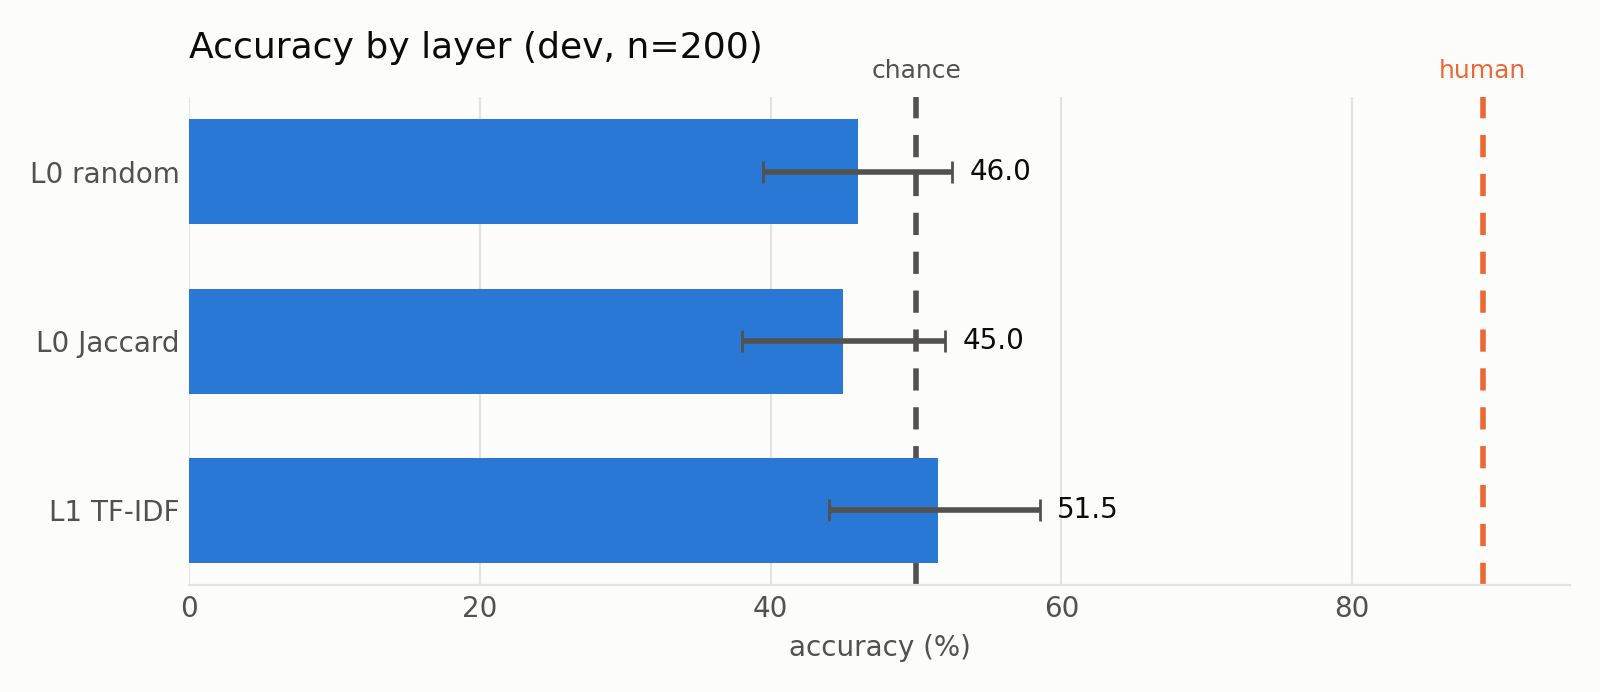

In [17]:
from task4.plots import load_results, ablation_chart, strata_chart
from IPython.display import Image, SVG, display

saved = load_results(RESULTS, "dev")
print("layers with saved dev results:", sorted(saved))

p = ablation_chart(saved, FIGURES / "ablation_dev.png",
                   title="Accuracy by layer (dev, n=200)", human_ceiling=89)
display(Image(filename=str(p)))

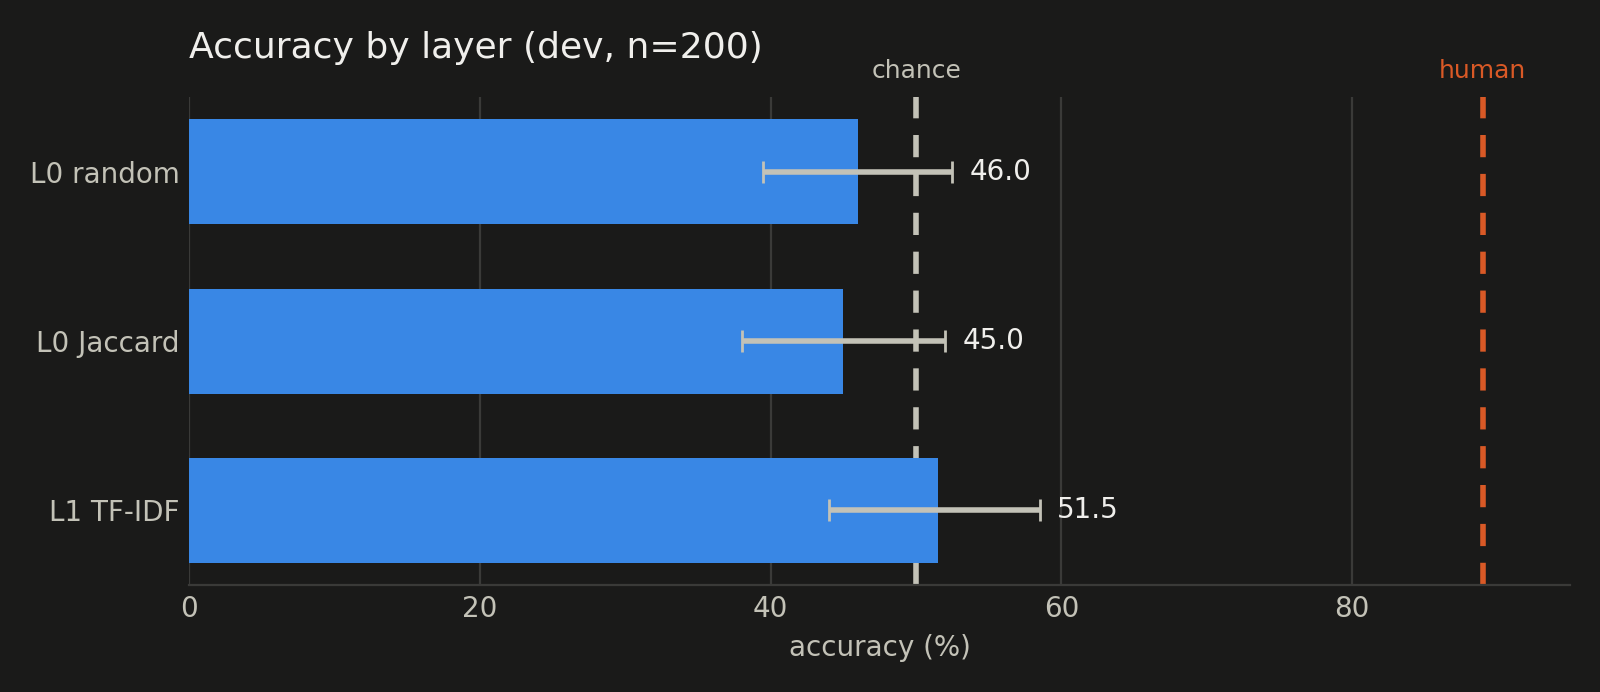

In [18]:
# The same figure in dark steps, for a dark slide template.
p = ablation_chart(saved, FIGURES / "ablation_dev_dark.png",
                   title="Accuracy by layer (dev, n=200)", human_ceiling=89, dark=True)
display(Image(filename=str(p)))

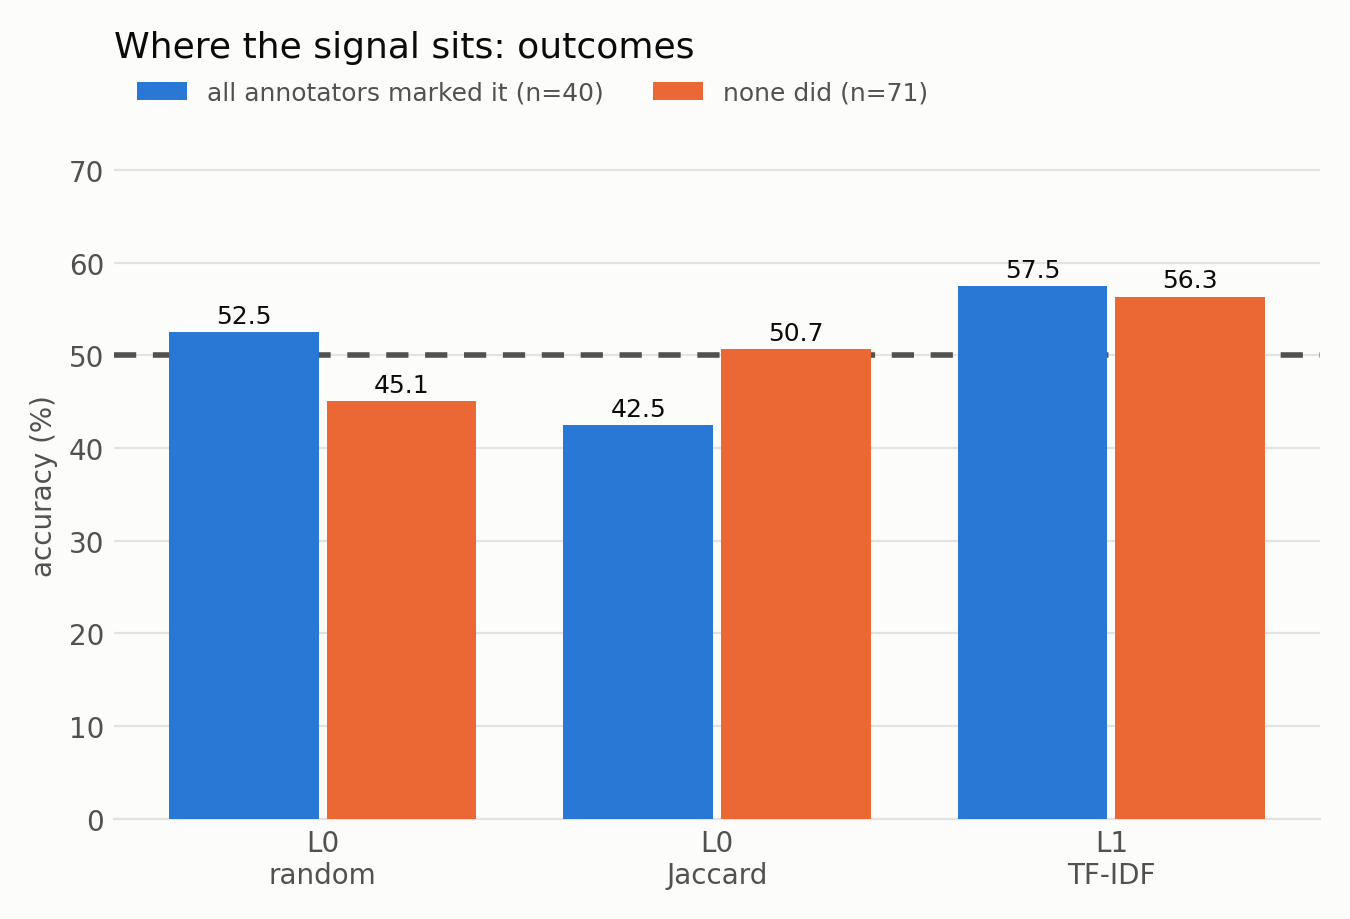

In [19]:
try:
    p = strata_chart(saved, FIGURES / "strata_outcomes_dev.png", aspect="outcomes")
    display(Image(filename=str(p)))
except ValueError as exc:
    print("strata chart needs runs carrying strata:", exc)

---
## 12. How the pieces connect

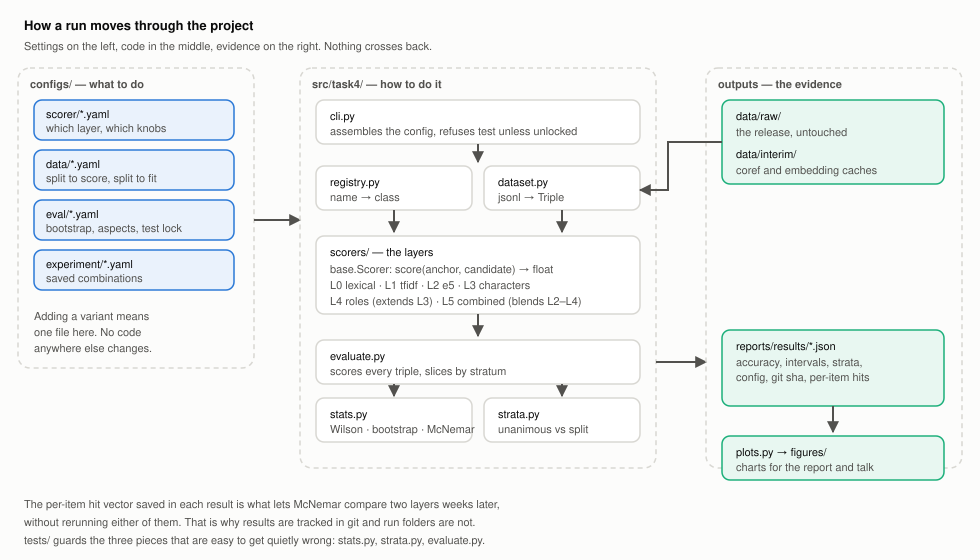

In [20]:
display(SVG(filename=str(FIGURES / "system_diagram.svg")))

---
## 13. Leaving the notebook

Everything above runs from the command line, with the same code and the same
statistics. The notebook is for understanding; the CLI is for the record,
because every CLI run writes a result file stamped with its config and commit.

```bash
# one layer, one split
python -m task4.cli scorer=l1_tfidf data=dev

# change a parameter without touching code
python -m task4.cli scorer=l4_roles scorer.params.agent_weight=0.7

# every layer, swept
make ablation

# the diagnostic, paired against the L2 backbone
make diagnostic

# the single held-out run, which refuses to start without the explicit unlock
python -m task4.cli --multirun experiment=ablation data=test eval.allow_test=true
```

**Next steps** are dated in `docs/PLAN.md`: L2 running by 2 November, L3 plus the
50-item coreference audit by 9 November, L4 and L5 by 16 November, configuration
frozen 19 November, the one test run on 20 November, writing and the video
through 25 November.